### Importation des librairies

In [10]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

print(tf.config.list_physical_devices('GPU'))

#Définition de la longueur et de la largeur de l'image
LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

#Chargement des images
observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')

[]


### Premier affichage

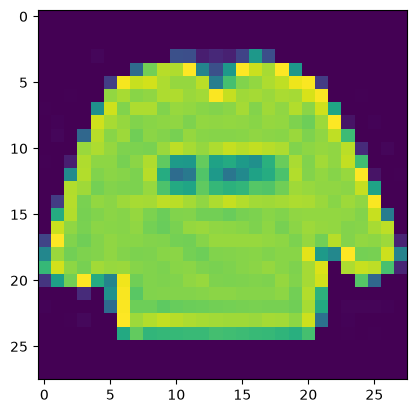

In [11]:
#On exclut la première colonne (les labels) pour constituer un tableau de pixels
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

# Préparation des données d'apprentissage

In [12]:
#On crée des catégories à l'aide du module Keras
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))
#Répartition des données d'entrainement en données d'apprentissage et données de validation
#80% de donnée d'apprentissage et 20% de donnée de validation
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [13]:
# On redimensionne les images au format 28*28 et on réalise un scaling sur les données des pixels
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], 
                                          LARGEUR_IMAGE, 
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], 
                                    LARGEUR_IMAGE, 
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

# Préparation des données de tests

In [14]:
#Preparation des données de tests
observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

### Première couche de convolution

In [15]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#1- Ajout de la couche de convolution comportant
# 32 filtres de de taille 3x3 (Kernel) parcourant l'image
# Une fonction d'activation de type ReLU (Rectified Linear Activation)
# Une image d'entrée de 28px * 28 px 
reseauNeurone1Convolution.add(Conv2D(32, 
                                     kernel_size=(3, 3), 
                                     activation='relu'))

#2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

#3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#5 - On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

#6 - Ajout d'un réseau de neurones composé de 128 neurones avec 
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#7 - Ajout d'un réseau de neurones composé de 10 neurones avec une 
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

# Compilation et apprentissage

In [16]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

In [17]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=12,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - accuracy: 0.8054 - loss: 0.5560 - val_accuracy: 0.8548 - val_loss: 0.4079
Epoch 2/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.8694 - loss: 0.3690 - val_accuracy: 0.8820 - val_loss: 0.3459
Epoch 3/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.8863 - loss: 0.3214 - val_accuracy: 0.8855 - val_loss: 0.3249
Epoch 4/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.8946 - loss: 0.2951 - val_accuracy: 0.8899 - val_loss: 0.3120
Epoch 5/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.9022 - loss: 0.2739 - val_accuracy: 0.8963 - val_loss: 0.2983
Epoch 6/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9075 - loss: 0.2584 - val_accuracy: 0.9011 - val_loss: 0.2828
Epoch 7/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.9136 - loss: 0.2423 - val_accuracy: 0.9043 - val_loss: 0.2697
Epoch 8/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.9180 - loss: 0.2278 - val_accu

### Résultats et affichages

In [18]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.24035146832466125
Précision: 0.9140999913215637


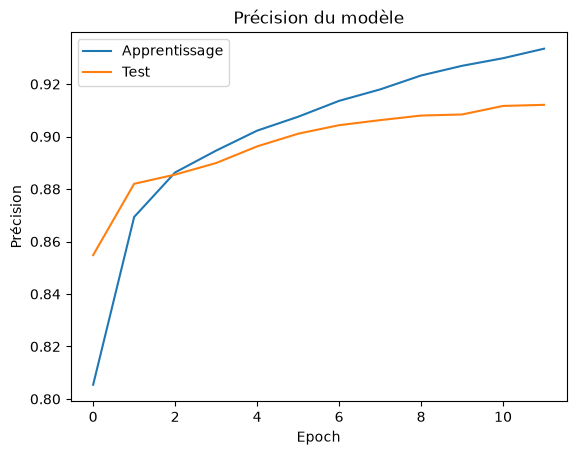

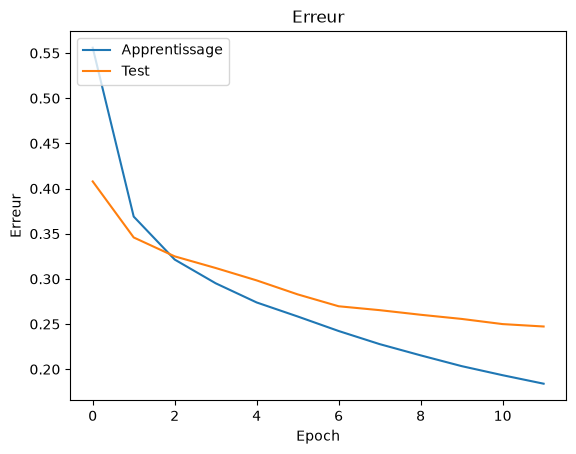

In [19]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

### Augmentation du nombre de données

In [21]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08,
)

In [22]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 13s 69ms/step - accuracy: 0.8293 - loss: 0.4606 - val_accuracy: 0.8412 - val_loss: 0.4285
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.7852 - loss: 0.5355

c:\Users\jojob\Desktop\Programmation\Machine Learning\420-5G4-ML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.7852 - loss: 0.5355 - val_accuracy: 0.8419 - val_loss: 0.4259
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 66ms/step - accuracy: 0.8480 - loss: 0.4111 - val_accuracy: 0.8586 - val_loss: 0.3844
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8906 - loss: 0.3125 - val_accuracy: 0.8552 - val_loss: 0.3835
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 13s 69ms/step - accuracy: 0.8554 - loss: 0.3849 - val_accuracy: 0.8639 - val_loss: 0.3645
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8516 - loss: 0.3500 - val_accuracy: 0.8624 - val_loss: 0.3696
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 13s 67ms/step - accuracy: 0.8613 - loss: 0.3725 - val_accuracy: 0.8621 - val_loss: 0.3693
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8516 - loss: 0.3922 - val_accuracy: 0.8637 - val_loss: 0.3729
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 66ms/step - accuracy: 0.8644 - loss: 0.3640 - val_accuracy: 0

### Sauvegarde du modele

In [23]:
#Sauvegarde du modèle
# Serialisation du modèle 
model_json = reseauNeurone1Convolution.to_json() 
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)
    
# Serialisation des poids
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !


# Modele plus performant

In [24]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

c:\Users\jojob\Desktop\Programmation\Machine Learning\420-5G4-ML\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Apprentissage

In [27]:
historique_apprentissage = reseauNeurones4Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 56s 293ms/step - accuracy: 0.8532 - loss: 0.4071 - val_accuracy: 0.8768 - val_loss: 0.3330
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8633 - loss: 0.4052 - val_accuracy: 0.8764 - val_loss: 0.3415
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 53s 282ms/step - accuracy: 0.8691 - loss: 0.3574 - val_accuracy: 0.8895 - val_loss: 0.2977
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8516 - loss: 0.4012 - val_accuracy: 0.8898 - val_loss: 0.2919
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 53s 284ms/step - accuracy: 0.8746 - loss: 0.3461 - val_accuracy: 0.8809 - val_loss: 0.3093
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8789 - loss: 0.3847 - val_accuracy: 0.8865 - val_loss: 0.3061
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 53s 285ms/step - accuracy: 0.8798 - loss: 0.3307 - val_accuracy: 0.8904 - val_loss: 0.2898
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8867 - loss: 0.3329 - 

In [28]:
#Sauvegarde du modèle
# Serialisation du modèle 
model_json = reseauNeurones4Convolution.to_json() 
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)
    
# Serialisation des poids
reseauNeurones4Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !


# Utilisation du modele

In [29]:
#Chargement de la description du modèle
fichier_json = open('modele/modele.json', 'r')
modele_json = fichier_json.read()
fichier_json.close()

#Chargement de la description des poids du modèle
from keras.models import model_from_json
modele = model_from_json(modele_json)
#Chargement des poids
modele.load_weights("modele/modele.weights.h5")

In [30]:
#Définition des catégories de classifications
classes = ["Un T-shirt/haut",
           "Un pantalon",
           "Un pull", 
           "Une robe",
           "Un manteau",
           "Des sandales",
           "Une chemise",
           "Des baskets", 
           "Un sac",
           "Des bottes de cheville"]

In [31]:
import numpy as np
from PIL import Image, ImageFilter


def load_and_preprocess_image(image_path, target_size=28, content_size=20):
    """
    Load an image, convert to grayscale, and preprocess for model input.
    
    Args:
        image_path: Path to the input image
        target_size: Size of the output square image (default: 28x28)
        content_size: Size of the resized content within the target (default: 20)
    
    Returns:
        numpy.ndarray: Preprocessed image array ready for model prediction
    """
    image = Image.open(image_path).convert('L')
    resized_img = resize_with_aspect_ratio(image, content_size)
    canvas = create_centered_image(resized_img, target_size)
    normalized_array = normalize_pixels(canvas)
    
    return normalized_array.reshape(1, target_size, target_size, 1)


def resize_with_aspect_ratio(image, target_dimension):
    """
    Resize image maintaining aspect ratio.
    
    Args:
        image: PIL Image object
        target_dimension: Target size for the longest dimension
    
    Returns:
        PIL Image: Resized and sharpened image
    """
    width, height = image.size
    
    if width > height:
        new_width = target_dimension
        new_height = max(1, round(target_dimension * height / width))
    else:
        new_height = target_dimension
        new_width = max(1, round(target_dimension * width / height))
    
    return image.resize((new_width, new_height), Image.LANCZOS).filter(ImageFilter.SHARPEN)


def create_centered_image(image, canvas_size):
    """
    Place image in the center of a white canvas.
    
    Args:
        image: PIL Image to center
        canvas_size: Size of the square canvas
    
    Returns:
        PIL Image: Image centered on white canvas
    """
    canvas = Image.new('L', (canvas_size, canvas_size), 255)
    
    img_width, img_height = image.size
    
    # Calculate centering offsets
    x_offset = (canvas_size - img_width) // 2
    y_offset = (canvas_size - img_height) // 2
    
    canvas.paste(image, (x_offset, y_offset))
    return canvas


def normalize_pixels(image):
    pixels = np.array(image.getdata(), dtype=np.float32)
    # Invert colors (white background to black) and normalize
    return (255 - pixels) / 255.0

In [48]:
image_array = load_and_preprocess_image("image.png")

probabilities = modele.predict(image_array)[0]
predicted_class = np.argmax(probabilities)

print(f"Selon moi l'image est : {classes[predicted_class]}\n")

for i, class_name in enumerate(classes):
    print(f"{class_name}: {probabilities[i] * 100:.2f}%")

C:\Users\jojob\AppData\Local\Temp\ipykernel_8572\94602248.py:72: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = np.array(image.getdata(), dtype=np.float32)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
Selon moi l'image est : Une robe

Un T-shirt/haut: 3.48%
Un pantalon: 0.22%
Un pull: 0.10%
Une robe: 95.57%
Un manteau: 0.06%
Des sandales: 0.05%
Une chemise: 0.34%
Des baskets: 0.01%
Un sac: 0.16%
Des bottes de cheville: 0.01%
